# Week 4 — Integrated Capstone Project
## Logistic Regression and Feature Scaling

**Datasets:** Cervical Cancer Risk Factors and Breast Cancer Wisconsin Diagnostic

### Central question
How does logistic regression perform when predicting a binary outcome, and how does feature scaling affect model fitting, coefficient interpretation, and predictive performance?

This notebook applies logistic regression to both capstone datasets using a common train/test and scaling workflow.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
    classification_report, roc_curve
)

RANDOM_STATE = 42
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def classification_metrics(model, X_test, y_test):
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    return {
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, prob)
    }


## 1. Dataset 1 — Cervical Cancer Risk Factors

For the cervical dataset, the target is `Biopsy`, a binary screening outcome. The analysis uses the available numeric risk-factor variables as predictors and excludes other screening outcome columns to reduce target leakage.


In [ ]:
cervical = pd.read_csv("risk_factors_cervical_cancer.csv")
cervical = cervical.replace(["?", ""], np.nan)

# Convert columns to numeric where possible
for col in cervical.columns:
    cervical[col] = pd.to_numeric(cervical[col], errors="coerce")

target_c = "Biopsy"

# Exclude other screening/diagnostic outcome variables from predictors
leakage_cols = [
    "Hinselmann", "Schiller", "Citology",
    "Dx:Cancer", "Dx:CIN", "Dx:HPV", "Dx"
]

drop_cols = [target_c] + [c for c in leakage_cols if c in cervical.columns]
Xc = cervical.drop(columns=drop_cols)
yc = cervical[target_c]

Xc = Xc.select_dtypes(include=np.number)
valid = yc.notna()
Xc, yc = Xc.loc[valid], yc.loc[valid].astype(int)

print("Class distribution:")
print(yc.value_counts())
print("\nPredictor count:", Xc.shape[1])


### 1.1 Train/test split


In [ ]:
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc, yc, test_size=0.20, stratify=yc, random_state=RANDOM_STATE
)


### 1.2 Logistic regression without feature scaling

This model provides a comparison point. Missing numeric values are imputed using the training data's median values. Because predictors can be on very different scales, this is compared directly with the standardized model below.


In [ ]:
logit_unscaled_c = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", LogisticRegression(max_iter=5000))
])

logit_unscaled_c.fit(Xc_train, yc_train)
unscaled_metrics_c = classification_metrics(
    logit_unscaled_c, Xc_test, yc_test
)
unscaled_metrics_c


### 1.3 Logistic regression with feature scaling

StandardScaler places numeric predictors on a comparable scale before logistic regression. This is especially important when regularization is used because the penalty otherwise depends on the measurement scale of each feature.


In [ ]:
logit_scaled_c = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    ("model", LogisticRegression(max_iter=5000))
])

logit_scaled_c.fit(Xc_train, yc_train)
scaled_metrics_c = classification_metrics(
    logit_scaled_c, Xc_test, yc_test
)
scaled_metrics_c


### 1.4 Tune the regularization strength


In [ ]:
param_grid = {
    "model__C": np.logspace(-3, 3, 13)
}

grid_c = GridSearchCV(
    logit_scaled_c,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=CV,
    n_jobs=-1
)
grid_c.fit(Xc_train, yc_train)

print("Best C:", grid_c.best_params_["model__C"])
print("Best cross-validated ROC-AUC:", grid_c.best_score_)

tuned_metrics_c = classification_metrics(
    grid_c.best_estimator_, Xc_test, yc_test
)
tuned_metrics_c


### 1.5 Confusion matrix and ROC curve


In [ ]:
pred_c = grid_c.best_estimator_.predict(Xc_test)
prob_c = grid_c.best_estimator_.predict_proba(Xc_test)[:, 1]

ConfusionMatrixDisplay.from_predictions(yc_test, pred_c)
plt.title("Cervical Cancer Risk Factors — Logistic Regression")
plt.show()

fpr_c, tpr_c, _ = roc_curve(yc_test, prob_c)
plt.figure()
plt.plot(fpr_c, tpr_c, label=f"ROC-AUC = {roc_auc_score(yc_test, prob_c):.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Cervical Dataset ROC Curve")
plt.legend()
plt.show()


## 2. Dataset 2 — Breast Cancer Wisconsin Diagnostic

The target is `diagnosis`, converted to 1 for malignant and 0 for benign. The identifier is excluded from the predictors. The remaining quantitative cell measurements are suitable for examining the effect of feature scaling in logistic regression.


In [ ]:
wdbc_cols = ["id", "diagnosis"] + [f"feature_{i}" for i in range(1,31)]
breast = pd.read_csv("wdbc.data", header=None, names=wdbc_cols)

yb = (breast["diagnosis"] == "M").astype(int)
Xb = breast.drop(columns=["id", "diagnosis"])

print("Class distribution:")
print(yb.value_counts())
print("\nPredictor count:", Xb.shape[1])


### 2.1 Train/test split


In [ ]:
Xb_train, Xb_test, yb_train, yb_test = train_test_split(
    Xb, yb, test_size=0.20, stratify=yb, random_state=RANDOM_STATE
)


### 2.2 Logistic regression without scaling


In [ ]:
logit_unscaled_b = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", LogisticRegression(max_iter=5000))
])

logit_unscaled_b.fit(Xb_train, yb_train)
unscaled_metrics_b = classification_metrics(
    logit_unscaled_b, Xb_test, yb_test
)
unscaled_metrics_b


### 2.3 Logistic regression with feature scaling


In [ ]:
logit_scaled_b = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    ("model", LogisticRegression(max_iter=5000))
])

logit_scaled_b.fit(Xb_train, yb_train)
scaled_metrics_b = classification_metrics(
    logit_scaled_b, Xb_test, yb_test
)
scaled_metrics_b


### 2.4 Tune regularization strength


In [ ]:
grid_b = GridSearchCV(
    logit_scaled_b,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=CV,
    n_jobs=-1
)
grid_b.fit(Xb_train, yb_train)

print("Best C:", grid_b.best_params_["model__C"])
print("Best cross-validated ROC-AUC:", grid_b.best_score_)

tuned_metrics_b = classification_metrics(
    grid_b.best_estimator_, Xb_test, yb_test
)
tuned_metrics_b


### 2.5 Confusion matrix and ROC curve


In [ ]:
pred_b = grid_b.best_estimator_.predict(Xb_test)
prob_b = grid_b.best_estimator_.predict_proba(Xb_test)[:, 1]

ConfusionMatrixDisplay.from_predictions(yb_test, pred_b)
plt.title("Breast Cancer Wisconsin Diagnostic — Logistic Regression")
plt.show()

fpr_b, tpr_b, _ = roc_curve(yb_test, prob_b)
plt.figure()
plt.plot(fpr_b, tpr_b, label=f"ROC-AUC = {roc_auc_score(yb_test, prob_b):.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Breast Dataset ROC Curve")
plt.legend()
plt.show()


## 3. Compare Scaling and Tuned Models


In [ ]:
comparison = pd.DataFrame([
    ["Cervical", "Unscaled Logistic Regression", unscaled_metrics_c],
    ["Cervical", "Scaled Logistic Regression", scaled_metrics_c],
    ["Cervical", "Tuned Scaled Logistic Regression", tuned_metrics_c],
    ["Breast", "Unscaled Logistic Regression", unscaled_metrics_b],
    ["Breast", "Scaled Logistic Regression", scaled_metrics_b],
    ["Breast", "Tuned Scaled Logistic Regression", tuned_metrics_b],
], columns=["Dataset", "Model", "Metrics"])

for metric in ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]:
    comparison[metric] = comparison["Metrics"].apply(lambda d: d[metric])

comparison.drop(columns="Metrics")


## 4. Coefficient Interpretation

For the scaled models, coefficients are measured on standardized predictor scales, making their magnitudes more comparable than coefficients from the unscaled model.

Use the following cells to inspect the coefficients of the tuned models.


In [ ]:
# Cervical coefficients
c_features = Xc.columns
c_coefs = pd.Series(
    grid_c.best_estimator_.named_steps["model"].coef_[0],
    index=c_features
).sort_values(key=np.abs, ascending=False)

c_coefs.head(15)


In [ ]:
# Breast coefficients
b_features = Xb.columns
b_coefs = pd.Series(
    grid_b.best_estimator_.named_steps["model"].coef_[0],
    index=b_features
).sort_values(key=np.abs, ascending=False)

b_coefs.head(15)


## 5. Interpretation for Milestone One

Discuss:

1. What changed when feature scaling was added?
2. Did scaling materially change predictive performance?
3. What value of `C` was selected through cross-validation?
4. Which predictors had the largest standardized coefficients?
5. How do precision and recall differ between the two datasets?
6. Why is ROC-AUC useful in addition to accuracy?
7. What do the confusion matrices show about false positives and false negatives?
8. How do the logistic-regression findings connect with the Week 1–3 regression analyses?

**Important:** These models are being used for machine-learning coursework. Their outputs should not be interpreted as clinical diagnoses or medical recommendations.


## 6. Conclusion

This Week 4 analysis demonstrates binary logistic regression and feature scaling on both capstone datasets. The comparison of unscaled, scaled, and cross-validated logistic regression provides evidence about the importance of putting predictors on comparable scales and selecting an appropriate regularization strength.


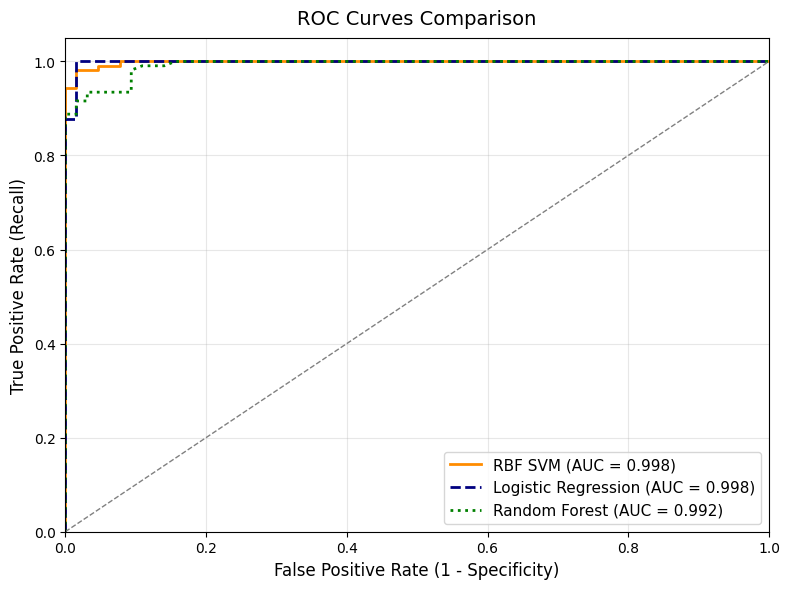

Plot saved as 'roc_curves.png'


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, auc

# 1. Load the Wisconsin Breast Cancer Dataset
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

# 2. Train-Test Split (Stratified to preserve class ratio)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# 3. Standardize Features (Required for Logistic Regression & SVM)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Train Models & Obtain Predicted Probabilities
# Model 1: Logistic Regression (Week 4)
log_reg = LogisticRegression(C=1.0, random_state=42)
log_reg.fit(X_train_scaled, y_train)
y_prob_log = log_reg.predict_proba(X_test_scaled)[:, 1]

# Model 2: RBF Support Vector Machine (Week 5)
svm_model = SVC(kernel='rbf', C=10, gamma=0.01, probability=True, random_state=42)
svm_model.fit(X_train_scaled, y_train)
y_prob_svm = svm_model.predict_proba(X_test_scaled)[:, 1]

# Model 3: Random Forest (Week 6)
rf_model = RandomForestClassifier(n_estimators=200, max_features='sqrt', random_state=42)
rf_model.fit(X_train, y_train)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

# 5. Compute ROC Curves & AUC Scores
fpr_log, tpr_log, _ = roc_curve(y_test, y_prob_log)
fpr_svm, tpr_svm, _ = roc_curve(y_test, y_prob_svm)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

auc_log = auc(fpr_log, tpr_log)
auc_svm = auc(fpr_svm, tpr_svm)
auc_rf = auc(fpr_rf, tpr_rf)

# 6. Plot ROC Curves Comparison
plt.figure(figsize=(8, 6))
plt.plot(fpr_svm, tpr_svm, color='darkorange', lw=2, label=f'RBF SVM (AUC = {auc_svm:.3f})')
plt.plot(fpr_log, tpr_log, color='navy', lw=2, linestyle='--', label=f'Logistic Regression (AUC = {auc_log:.3f})')
plt.plot(fpr_rf, tpr_rf, color='green', lw=2, linestyle=':', label=f'Random Forest (AUC = {auc_rf:.3f})')
plt.plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--')  # Chance baseline

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Recall)', fontsize=12)
plt.title('ROC Curves Comparison', fontsize=14, pad=10)
plt.legend(loc="lower right", fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()

# 7. Save PNG File to Insert into Microsoft Word
plt.savefig('roc_curves.png', dpi=300, bbox_inches='tight')
plt.show()

print("Plot saved as 'roc_curves.png'")

/var/folders/8k/b103nq_96pd8y7y6gdwpgjsr0000gn/T/ipykernel_20343/1172652179.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances.values, y=importances.index, palette='Blues_r')


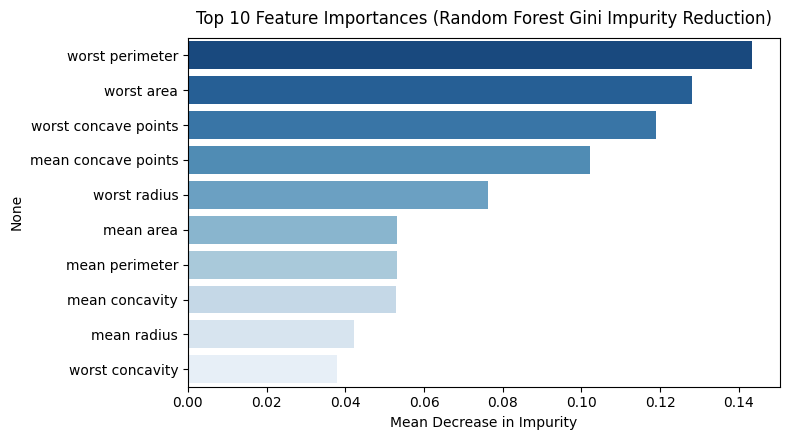

Saved 'feature_importance.png'


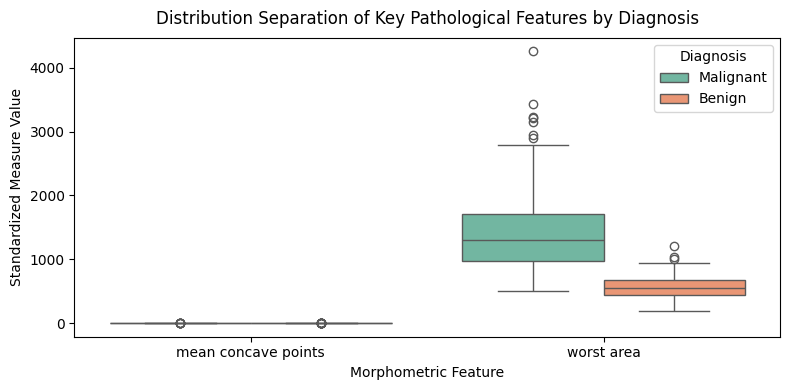

Saved 'feature_boxplots.png'


In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import RandomForestClassifier

# Load dataset
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['diagnosis'] = data.target

# ---------------------------------------------------------
# NEW FIGURE A: Feature Importance Ranking (Random Forest)
# ---------------------------------------------------------
X = df.drop(columns=['diagnosis'])
y = df['diagnosis']

rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X, y)

# Get top 10 most important features
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 4.5))
sns.barplot(x=importances.values, y=importances.index, palette='Blues_r')
plt.title('Top 10 Feature Importances (Random Forest Gini Impurity Reduction)', fontsize=12, pad=10)
plt.xlabel('Mean Decrease in Impurity', fontsize=10)
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved 'feature_importance.png'")

# ---------------------------------------------------------
# NEW FIGURE B: Feature Distribution Boxplots by Diagnosis
# ---------------------------------------------------------
plt.figure(figsize=(8, 4))
df_melt = pd.melt(df, id_vars=['diagnosis'], value_vars=['mean concave points', 'worst area'])
df_melt['diagnosis'] = df_melt['diagnosis'].map({0: 'Malignant', 1: 'Benign'})

sns.boxplot(x='variable', y='value', hue='diagnosis', data=df_melt, palette='Set2')
plt.title('Distribution Separation of Key Pathological Features by Diagnosis', fontsize=12, pad=10)
plt.xlabel('Morphometric Feature', fontsize=10)
plt.ylabel('Standardized Measure Value', fontsize=10)
plt.legend(title='Diagnosis')
plt.tight_layout()
plt.savefig('feature_boxplots.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved 'feature_boxplots.png'")